# 156 sensors split by operating stage

Goal: before adding variety / physics to the fake data, know **per stage** how each of the
156 kept sensors (155 + FIRC 1,2 natural gas) behaves, and whether the 106 "other" sensors
can be computed from the 50 stage-rule sensors inside that stage.

* Stage labels: `04_synthetic_data/library/traces_1min.parquet` (latest rules; Shut-down split
  into Cooling / At ambient).
* Sensor values: `excel_sensors/x1min.parquet` (1-min means of the Excel-listed sensors).
* Sensor list: same 156 as `stage_vs_other_correlation.ipynb`.

Outputs in `03_data_analysis/sensors_by_stage/`.

In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message="An input array is constant")
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 60)

ROOT = Path.cwd()
if ROOT.name != "03_data_analysis":
    ROOT = ROOT / "03_data_analysis"
PROJ = ROOT.parent
LIB = PROJ / "04_synthetic_data" / "library"
OUT = ROOT / "sensors_by_stage"
(OUT / "data").mkdir(parents=True, exist_ok=True)

verdict = pd.read_csv(ROOT / "excel_sensors" / "verdict.csv")
DROP = ["Not traceable", "Not usable", "Back-up twin", "Duplicate row"]
keep = pd.concat([verdict[~verdict["verdict"].isin(DROP)],
                  verdict[verdict["column"] == "ct_FIRC_12_PV_ProcessValue"]]).drop_duplicates("column").set_index("column")

STAGE_SIGNALS = {
    "Stack temperature": [c for c in keep.index if c.startswith("TIR_4_6_")],
    "String current": [f"PLC_hostSetp_ctrl_ctEIRC4{i}_rCurrMonitor" for i in range(1, 6)],
    "Heater power": ["EIRC_2_01_ActV_In_ThreePhasePower"],
    "Air pressure": ["PIR_2_02"],
    "Air flow": ["ct_FIRC_111_PV_ProcessValue", "ct_FIRC_112_PV_ProcessValue"],
    "N2 flow": ["ct_FIRC_13_PV_ProcessValue"],
    "H2 flow": ["ct_FIRC_15_PV_ProcessValue"],
    "Natural gas flow": ["ct_FIRC_12_PV_ProcessValue"],
    "Ambient proxy": ["TIR_1_1_1", "TIR_1_2_1", "TIR_1_3", "TIR_1_4_1"],
}
stage_cols = [c for cols in STAGE_SIGNALS.values() for c in cols]
other_cols = [c for c in keep.index if c not in stage_cols]
role = {c: r for r, cols in STAGE_SIGNALS.items() for c in cols}
tag = keep["tag"].to_dict()
print(f"Sensors: {len(keep)}  = stage-rule {len(stage_cols)} + other {len(other_cols)}")

Sensors: 156  = stage-rule 50 + other 106


In [ ]:
x = pd.read_parquet(ROOT / "excel_sensors" / "x1min.parquet")
lab = pd.read_parquet(LIB / "traces_1min.parquet")[["stage", "sub_stage", "operation", "phase", "episode_id", "usable"]]
x = x.drop(columns=["stage", "phase"]).join(lab, how="inner")

d = x[stage_cols + other_cols].apply(pd.to_numeric, errors="coerce")
d = d.where(d != -1)
tc = STAGE_SIGNALS["Stack temperature"]
d[tc] = d[tc].where((d[tc] > 0) & (d[tc] < 1000))

# 7 stage groups: Shut-down split by sub-stage (as in pattern_generator)
grp = x["stage"].copy()
sd = grp == "Shut-down"
grp[sd] = np.where(x.loc[sd, "sub_stage"].str.startswith("At ambient"), "Shut-down (At ambient)", "Shut-down (Cooling)")
STAGES = ["Idle", "Start-up", "Hot standby", "Thermal adjustment", "Part load",
          "Shut-down (Cooling)", "Shut-down (At ambient)"]
x["group"] = grp

folds = pd.read_csv(LIB / "folds_days.csv")
fold_of_day = dict(zip(pd.to_datetime(folds["day"]).dt.date, folds["fold"]))
x["fold"] = [fold_of_day.get(t.date(), "?") for t in x.index]

summary = pd.DataFrame({
    "minutes": x["group"].value_counts(),
    "hours": (x["group"].value_counts() / 60).round(1),
    "episodes": x.groupby("group")["episode_id"].nunique(),
    "days": x.groupby("group").apply(lambda g: len(set(g.index.date))),
    "folds": x.groupby("group")["fold"].nunique(),
}).reindex(STAGES)
display(summary)

,minutes,hours,episodes,days,folds
group,,,,,
Idle,1258,21.0,2,1,1
Start-up,8935,148.9,14,17,5
Hot standby,17839,297.3,26,23,4
Thermal adjustment,2746,45.8,18,12,4
Part load,268,4.5,10,5,3
Shut-down (Cooling),18472,307.9,14,23,5
Shut-down (At ambient),5292,88.2,8,8,5


## 1. Split the data: one file per stage
Each file holds the 156 sensors (Excel tag names) at 1 minute plus the labels, so a stage can be
loaded on its own: `pd.read_parquet("sensors_by_stage/data/3_Hot_standby.parquet")`.

In [ ]:
names = {c: tag[c] for c in stage_cols + other_cols}
files = []
for i, s in enumerate(STAGES, 1):
    m = x["group"] == s
    part = d.loc[m].rename(columns=names)
    part.insert(0, "episode_id", x.loc[m, "episode_id"])
    part.insert(1, "stage", x.loc[m, "stage"])
    part.insert(2, "sub_stage", x.loc[m, "sub_stage"])
    part.insert(3, "operation", x.loc[m, "operation"])
    part.insert(4, "phase", x.loc[m, "phase"])
    fn = f"{i}_{s.replace(' (', '_').replace(')', '').replace(' ', '_')}.parquet"
    part.to_parquet(OUT / "data" / fn)
    files.append({"stage": s, "file": f"data/{fn}", "rows": len(part), "columns": part.shape[1]})
sensor_map = pd.DataFrame({"tag": [tag[c] for c in stage_cols + other_cols],
                           "raw_column": stage_cols + other_cols,
                           "role": ["stage-rule (" + role[c] + ")" if c in role else "other" for c in stage_cols + other_cols],
                           "area": keep.loc[stage_cols + other_cols, "area"].values,
                           "verdict": keep.loc[stage_cols + other_cols, "verdict"].values})
cache_cols = set(pd.read_parquet(LIB / "sensors_1min.parquet").columns)
sensor_map["in_filler_cache"] = sensor_map["raw_column"].isin(cache_cols)
sensor_map.to_csv(OUT / "sensor_map.csv", index=False)
display(pd.DataFrame(files))
print("Not copied by pattern_filler today (missing from its cache):",
      (~sensor_map["in_filler_cache"]).sum(), "sensors —",
      sensor_map.loc[~sensor_map["in_filler_cache"]].groupby("role").size().to_dict())

,stage,file,rows,columns
0,Idle,data/1_Idle.parquet,1258,161
1,Start-up,data/2_Start-up.parquet,8935,161
2,Hot standby,data/3_Hot_standby.parquet,17839,161
3,Thermal adjustment,data/4_Thermal_adjustment.parquet,2746,161
4,Part load,data/5_Part_load.parquet,268,161
5,Shut-down (Cooling),data/6_Shut-down_Cooling.parquet,18472,161
6,Shut-down (At ambient),data/7_Shut-down_At_ambient.parquet,5292,161


Not copied by pattern_filler today (missing from its cache): 42 sensors — {'other': 42}


## 2. What every sensor does inside every stage
Coverage, typical band (p5–p95) and how much of the sensor's whole range it uses in that stage.
**Flat** = uses < 3 % of its own whole-period range (p1–p99) in that stage.

In [ ]:
lo, hi = d.quantile(0.01), d.quantile(0.99)
full = (hi - lo).replace(0, np.nan)
rows = []
for s in STAGES:
    m = x["group"] == s
    q = d.loc[m].quantile([0.05, 0.5, 0.95])
    cov = d.loc[m].notna().mean()
    rate = d.loc[m].diff().abs().where(x.loc[m, "episode_id"].eq(x.loc[m, "episode_id"].shift()), axis=0).median()
    for c in d.columns:
        rows.append({"stage": s, "tag": tag[c], "column": c, "role": "stage-rule" if c in role else "other",
                     "coverage_pct": round(100 * cov[c], 1),
                     "p5": q.loc[0.05, c], "median": q.loc[0.5, c], "p95": q.loc[0.95, c],
                     "use_of_range_pct": round(100 * (q.loc[0.95, c] - q.loc[0.05, c]) / full[c], 1) if pd.notna(full[c]) else np.nan,
                     "median_step_per_min": rate[c]})
stats = pd.DataFrame(rows)

def behaviour(r):
    if r["coverage_pct"] < 30:
        return "No data"
    if pd.isna(r["use_of_range_pct"]) or r["use_of_range_pct"] < 3:
        return "Flat"
    return "Moving"

stats["behaviour"] = stats.apply(behaviour, axis=1)
stats.to_csv(OUT / "stage_stats.csv", index=False)
beh = stats.pivot(index="tag", columns="stage", values="behaviour")[STAGES]
display(pd.crosstab(stats["stage"], [stats["role"], stats["behaviour"]]).reindex(STAGES))

role                   other                stage-rule       
behaviour               Flat Moving No data       Flat Moving
stage                                                        
Idle                      31     54      21         12     38
Start-up                  22     79       5          6     44
Hot standby                9     78      19          8     42
Thermal adjustment        15     91       0          6     44
Part load                 14     92       0          3     47
Shut-down (Cooling)       13     78      15          7     43
Shut-down (At ambient)    35     55      16          7     43

## 3. Can the 106 other sensors be computed from the 50 inside each stage?
Per stage and per other sensor: a straight-line model (Ridge) and a curve model
(gradient boosting) from the 50 stage-rule sensors. Scored on **held-out runs** (folds F1–F5;
where a stage has < 3 folds, held-out episodes). R² = share of the sensor's movement the 50 explain
on data the model never saw. Flat / no-data cells are not modelled.

In [ ]:
def cv_r2(X, y, groups, model):
    ug = pd.unique(groups)
    pred = pd.Series(np.nan, index=y.index)
    for g in ug:
        te = groups == g
        tr = ~te
        if tr.sum() < 50 or te.sum() < 5:
            continue
        model.fit(X[tr], y[tr])
        pred[te] = model.predict(X[te])
    ok = pred.notna()
    if ok.sum() < 30 or y[ok].var() == 0:
        return np.nan, ok.mean()
    return 1 - ((y[ok] - pred[ok]) ** 2).sum() / ((y[ok] - y[ok].mean()) ** 2).sum(), ok.mean()


res = []
for s in STAGES:
    m = (x["group"] == s).values
    xs = d.loc[m, stage_cols]
    xs = xs.loc[:, xs.notna().mean() >= 0.5]
    xs = xs.fillna(xs.median())
    g = x.loc[m, "fold"].values
    gname = "run fold"
    if len(pd.unique(g)) < 3:
        g, gname = x.loc[m, "episode_id"].values, "episode"
    n_groups = len(pd.unique(g))
    step = max(1, int(m.sum() // 6000))          # boosting on ≤ ~6000 minutes per stage
    for c in other_cols:
        b = beh.loc[tag[c], s]
        r = {"stage": s, "tag": tag[c], "column": c, "behaviour": b, "held_out_by": gname, "groups": n_groups}
        if b != "Moving" or n_groups < 3:
            res.append(r); continue
        y = d.loc[m, c]
        ok = y.notna().values
        X, Y, G = xs.values[ok], y[ok].reset_index(drop=True), g[ok]
        r["r2_line"], _ = cv_r2(X, Y, G, make_pipeline(StandardScaler(), Ridge(alpha=1.0)))
        idx = np.arange(len(Y))[::step]
        r["r2_curve"], _ = cv_r2(X[idx], Y.iloc[idx].reset_index(drop=True), G[idx],
                                 HistGradientBoostingRegressor(max_iter=150, learning_rate=0.1, max_leaf_nodes=15))
        sp = xs[ok].corrwith(y[ok], method="spearman").abs()
        r["best_stage_sensor"] = tag[sp.idxmax()] if sp.notna().any() else None
        r["best_r"] = round(sp.max(), 3) if sp.notna().any() else np.nan
        res.append(r)
    print(f"{s:24s} done ({n_groups} {gname}s)")
res = pd.DataFrame(res)
res["r2_best"] = res[["r2_line", "r2_curve"]].max(axis=1).clip(lower=-1).round(3)
res["best_model"] = np.where(res["r2_line"].fillna(-9) >= res["r2_curve"].fillna(-9) - 0.02, "line", "curve")

Idle                     done (2 episodes)


Start-up                 done (5 run folds)


Hot standby              done (4 run folds)


Thermal adjustment       done (4 run folds)


Part load                done (3 run folds)


Shut-down (Cooling)      done (5 run folds)


Shut-down (At ambient)   done (5 run folds)


## 4. One class and one fake-data recipe per (stage, sensor)
| Class | Rule | Recipe for fake data |
|---|---|---|
| Flat | uses < 3 % of its range | stage level (+ real noise) |
| Follows the 50 | held-out R² ≥ 0.9 | compute from the 50 with the stage model |
| Partly follows | 0.6 ≤ R² < 0.9 | stage model + copied real wiggle (residual) |
| Own behaviour | R² < 0.6 | copy a real piece of the same stage & gas phase |
| Too few examples | < 3 runs/episodes | copy real (cannot test a model) |
| No data | < 30 % filled | leave out / flag |

In [ ]:
def klass(r):
    if r["behaviour"] in ("Flat", "No data"):
        return r["behaviour"]
    if r["groups"] < 3:
        return "Too few examples"
    v = r["r2_best"]
    if pd.isna(v):
        return "Too few examples"
    return "Follows the 50" if v >= 0.9 else "Partly follows" if v >= 0.6 else "Own behaviour"

RECIPE = {"Flat": "Stage level + real noise", "Follows the 50": "Compute from the 50 (stage model)",
          "Partly follows": "Stage model + copied real wiggle", "Own behaviour": "Copy real piece (same stage & phase)",
          "Too few examples": "Copy real piece", "No data": "Leave out / flag"}
res["class"] = res.apply(klass, axis=1)
res["recipe"] = res["class"].map(RECIPE)
res = res.merge(sensor_map[["raw_column", "area", "in_filler_cache"]], left_on="column", right_on="raw_column").drop(columns="raw_column")
res.to_csv(OUT / "other_sensors_by_stage.csv", index=False)

CLASSES = ["Follows the 50", "Partly follows", "Own behaviour", "Flat", "Too few examples", "No data"]
counts = pd.crosstab(res["stage"], res["class"]).reindex(index=STAGES, columns=CLASSES, fill_value=0)
counts.to_csv(OUT / "class_counts.csv")
display(counts)
matrix = res.pivot(index="tag", columns="stage", values="class")[STAGES]
matrix = matrix.join(keep.set_index("tag")["area"]).sort_values(["area"]).rename_axis("tag")
matrix.to_csv(OUT / "class_matrix.csv")

class,Follows the 50,Partly follows,Own behaviour,Flat,Too few examples,No data
stage,,,,,,
Idle,0,0,0,31,54,21
Start-up,27,23,29,22,0,5
Hot standby,22,16,40,9,0,19
Thermal adjustment,16,22,53,15,0,0
Part load,5,2,85,14,0,0
Shut-down (Cooling),33,17,28,13,0,15
Shut-down (At ambient),0,20,35,35,0,16


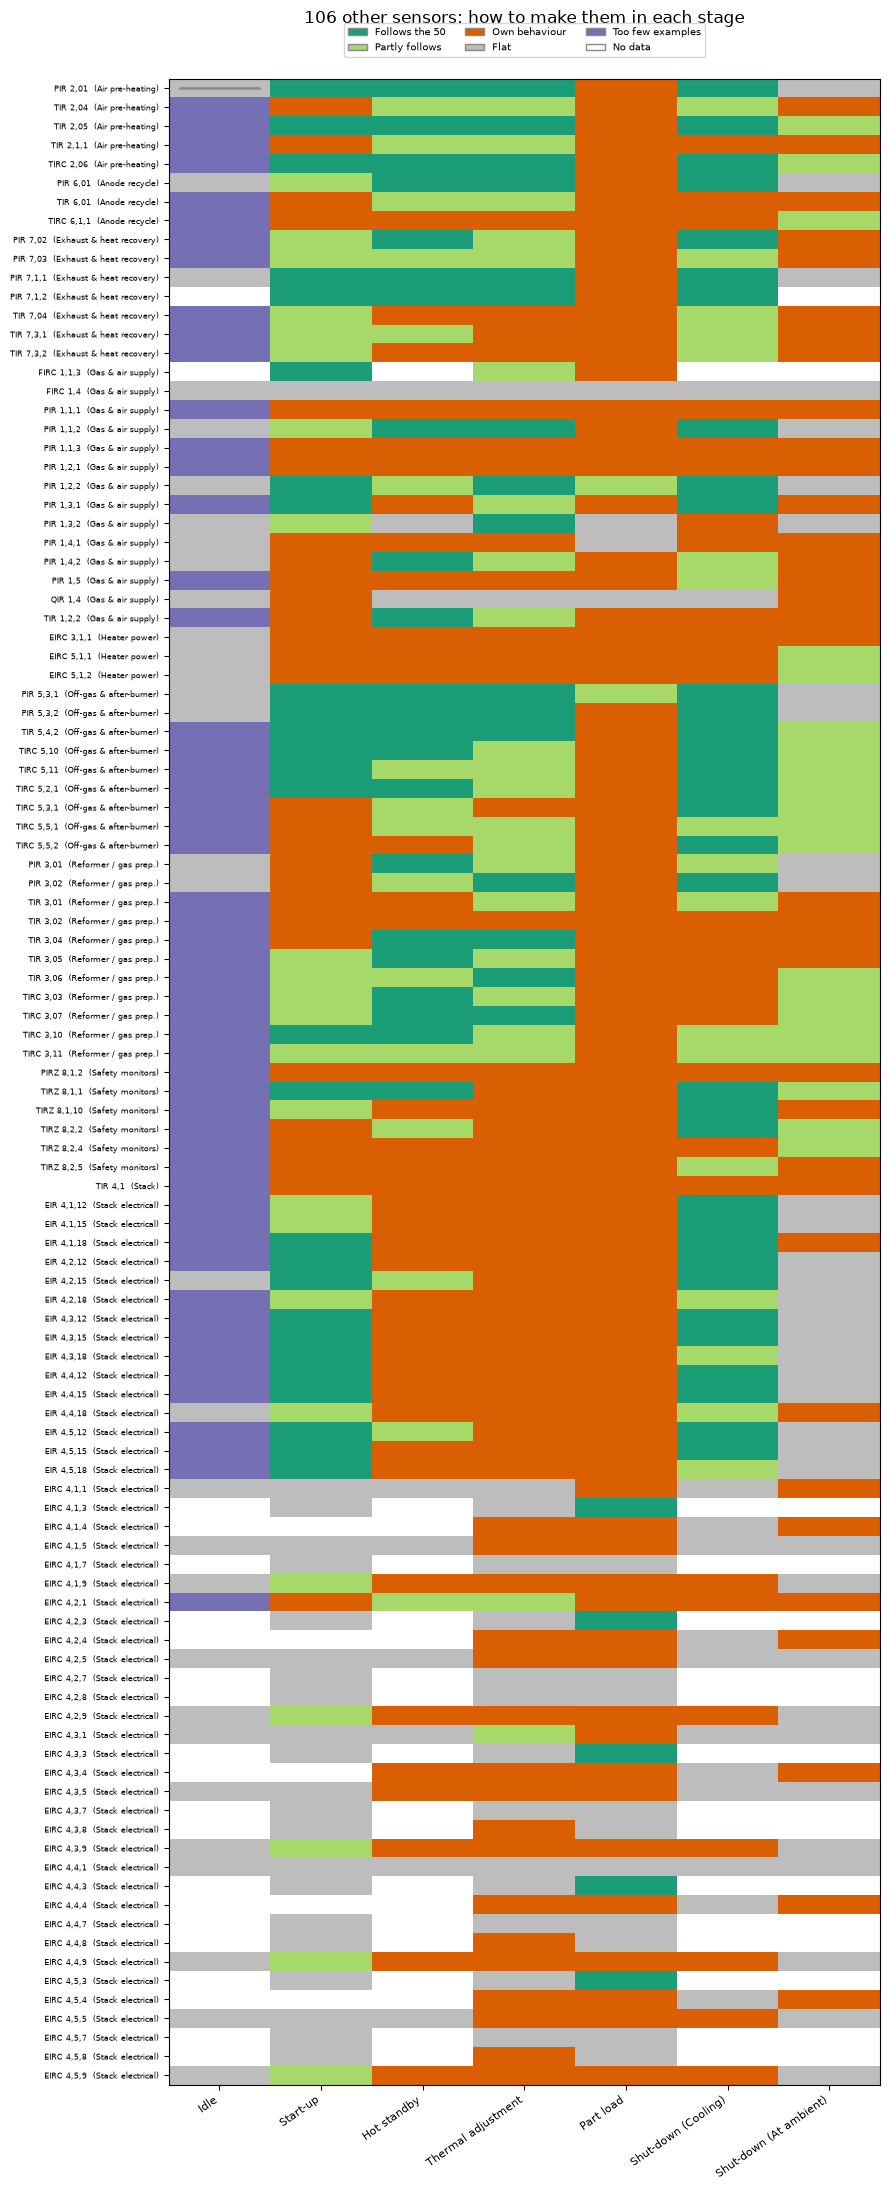

In [ ]:
COL = {"Follows the 50": "#1b9e77", "Partly follows": "#a6d96a", "Own behaviour": "#d95f02",
       "Flat": "#bdbdbd", "Too few examples": "#7570b3", "No data": "#ffffff"}
code = {k: i for i, k in enumerate(CLASSES)}
from matplotlib.colors import ListedColormap
mm = matrix[STAGES].replace(code).astype(float)
fig, ax = plt.subplots(figsize=(9, 22))
ax.imshow(mm.values, cmap=ListedColormap([COL[k] for k in CLASSES]), vmin=-0.5, vmax=len(CLASSES) - 0.5, aspect="auto")
ax.set_xticks(range(len(STAGES)), STAGES, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(mm)), [f"{t}  ({a})" for t, a in zip(mm.index, matrix["area"])], fontsize=5.5)
for k in CLASSES:
    ax.bar(0, 0, color=COL[k], label=k, edgecolor="#888")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=3, fontsize=7)
ax.set_title("106 other sensors: how to make them in each stage", pad=40)
fig.tight_layout()
fig.savefig(OUT / "class_matrix.png", dpi=130)
plt.show()

## 5. Same sensor, different stage
How often does a sensor change class between stages? And sensors that follow the 50 in every
stage where they move (one model family for all stages).

In [ ]:
moving = matrix[STAGES]
n_follow = (moving == "Follows the 50").sum(axis=1)
n_own = (moving == "Own behaviour").sum(axis=1)
n_mod = moving.isin(["Follows the 50", "Partly follows", "Own behaviour"]).sum(axis=1)
per_sensor = pd.DataFrame({"area": matrix["area"], "stages_follow": n_follow, "stages_partly": (moving == "Partly follows").sum(axis=1),
                           "stages_own": n_own, "stages_flat": (moving == "Flat").sum(axis=1), "stages_tested": n_mod})
per_sensor["overall"] = np.select(
    [(n_mod > 0) & (n_own == 0) & (n_follow == n_mod), n_own == 0, n_own >= 3],
    ["Always follows the 50", "Follows / partly", "Mostly own behaviour"], "Mixed")
per_sensor.to_csv(OUT / "per_sensor_overall.csv")
display(per_sensor["overall"].value_counts())
display(pd.crosstab(per_sensor["area"], per_sensor["overall"], margins=True))

overall
Mostly own behaviour     56
Mixed                    35
Follows / partly         10
Always follows the 50     5
Name: count, dtype: int64

overall,Always follows the 50,Follows / partly,Mixed,Mostly own behaviour,All
area,,,,,
Air pre-heating,0,0,3,2,5
Anode recycle,0,0,1,2,3
Exhaust & heat recovery,0,0,4,3,7
Gas & air supply,0,2,4,8,14
Heater power,0,0,0,3,3
Off-gas & after-burner,0,1,6,2,9
Reformer / gas prep.,0,0,7,4,11
Safety monitors,0,0,1,5,6
Stack,0,0,0,1,1


In [ ]:
own = res[res["class"] == "Own behaviour"].sort_values(["stage", "r2_best"])
display(own[["stage", "tag", "area", "r2_line", "r2_curve", "best_stage_sensor", "best_r"]].round(2))

,stage,tag,area,r2_line,r2_curve,best_stage_sensor,best_r
270,Hot standby,"EIR 4,1,12",Stack electrical,-4.46,-1.01,"TIR 4,6,20",0.15
275,Hot standby,"EIR 4,2,18",Stack electrical,-52.82,-1.23,"TIR 4,6,20",0.27
290,Hot standby,"EIRC 4,1,9",Stack electrical,-6.93,-1.32,"TIR 4,6,20",0.44
297,Hot standby,"EIRC 4,2,9",Stack electrical,-7.19,-1.39,"PIR 2,02",0.30
304,Hot standby,"EIRC 4,3,9",Stack electrical,-7.05,-1.37,"TIR 4,6,20",0.25
...,...,...,...,...,...,...,...
337,Thermal adjustment,"TIR 7,04",Exhaust & heat recovery,-0.04,0.45,"TIR 4,6,26",0.76
356,Thermal adjustment,"TIRC 6,1,1",Anode recycle,0.46,0.34,"TIR 4,6,11",0.70
386,Thermal adjustment,"EIR 4,4,15",Stack electrical,-2.49,0.48,"TIR 4,6,14",0.81
346,Thermal adjustment,"TIR 7,3,2",Exhaust & heat recovery,0.31,0.49,"TIR 4,6,26",0.79


## 6. Stage ranges of the 50 stage-rule sensors
These bands are the guard rails for the variety and physics layers: a varied or physics-made
curve must stay inside the real band of its stage (or be flagged).

In [ ]:
st50 = stats[stats["role"] == "stage-rule"].pivot(index="tag", columns="stage", values="median")[STAGES]
st50.round(2).to_csv(OUT / "stage_rule_sensor_medians.csv")
display(st50.round(1))

stage,Idle,Start-up,Hot standby,Thermal adjustment,Part load,Shut-down (Cooling),Shut-down (At ambient)
tag,,,,,,,
"EIRC 2,01",9.1,15085.6,9568.2,11436.5,8557.7,0.2,61.0
"EIRC 4,1,2",0.0,0.0,0.0,0.0,6.5,0.0,0.0
"EIRC 4,2,2",0.0,0.0,0.0,0.0,6.3,0.0,0.0
"EIRC 4,3,2",0.0,0.0,0.0,0.0,6.5,0.0,0.0
"EIRC 4,4,2",0.0,0.0,0.0,0.0,5.5,0.0,0.0
"EIRC 4,5,2",0.0,0.0,0.0,0.0,6.3,0.0,0.0
"FIRC 1,1,1",0.0,3000.0,3000.1,3000.3,4499.8,2999.8,0.0
"FIRC 1,1,2",0.0,3000.0,3000.1,3000.2,4499.7,2999.9,0.0
"FIRC 1,2",0.0,0.0,0.0,0.0,311.9,0.0,0.0


In [ ]:
print("Files in", OUT)
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUT)}  ({p.stat().st_size/1e6:.2f} MB)")

Files in C:\Users\mrgur\Guru_prasaath\06_Projects\01_POC\03_data_analysis\sensors_by_stage
  class_counts.csv  (0.00 MB)
  class_matrix.csv  (0.01 MB)
  class_matrix.png  (0.26 MB)
  data\1_Idle.parquet  (1.05 MB)
  data\2_Start-up.parquet  (7.97 MB)
  data\3_Hot_standby.parquet  (13.54 MB)
  data\4_Thermal_adjustment.parquet  (2.60 MB)
  data\5_Part_load.parquet  (0.39 MB)
  data\6_Shut-down_Cooling.parquet  (15.01 MB)
  data\7_Shut-down_At_ambient.parquet  (3.22 MB)
  other_sensors_by_stage.csv  (0.13 MB)
  per_sensor_overall.csv  (0.01 MB)
  sensor_map.csv  (0.01 MB)
  stage_rule_sensor_medians.csv  (0.00 MB)
  stage_stats.csv  (0.14 MB)
